# IAU Project - Phase 2: Preprocessing, Feature Selection and Pipeline

Phase 2 prepares numerical data, compares feature-selection methods and reuses
fitted preprocessing on held-out devices.

## Team Contributions

- Dmytro Petrenko: 50%
- Oleh Serdiukov: 50%


In [1]:
from pathlib import Path
import json
import warnings
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
    PowerTransformer, QuantileTransformer, OneHotEncoder)
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning

DATA = Path("data") if Path("data").is_dir() else Path("../data")
if not DATA.is_dir():
    raise FileNotFoundError("Run from the repository root or notebooks/ with data/ available.")
FINAL_DIR = DATA / "processed" / "phase2_final"
SEED = 42
TOP_K = 20
SPLIT_CONFIG = {"n_splits": 1, "test_size": 0.20, "random_state": SEED}


## 2.1 - Data Preprocessing

### 2.1(A) - Integration and device-based train/test split

We removed exact duplicates, normalized IDs and LEFT JOINed unit metadata using Phase 1 rules. We retained unmatched and suspicious records and left ambiguous dates unresolved.

We used `GroupShuffleSplit(test_size=0.20, random_state=42)` so readings from one device cannot appear in both sets. Different reading counts per device mean the row split is not exactly 80/20.


In [2]:
readings_raw = pd.read_csv(DATA / "readings.csv", sep="\t")
readings = readings_raw.drop_duplicates().copy()
units = pd.read_csv(DATA / "units.csv")

readings.index.name = "reading_row_id"

ids = readings["unitId"].astype("string").str.strip()
assert ids.str.fullmatch(r"U[0-9]+", na=False).all()

readings["unit_key"] = pd.to_numeric(ids.str[1:]).astype("int64")
units["unit_key"] = pd.to_numeric(units["unitId"]).astype("int64")

assert readings[["unitId", "unit_key"]].drop_duplicates()["unit_key"].is_unique
assert units["unit_key"].notna().all() and units["unit_key"].is_unique
assert readings["Failure"].isin([0, 1]).all()

In [3]:
joined_data = (
    readings.reset_index()
    .merge(
        units.drop(columns="unitId"),
        on="unit_key",
        how="left",
        validate="many_to_one",
        indicator="device_match",
        sort=False,
    )
    .set_index("reading_row_id")
)

joined_data["unit_metadata_missing"] = joined_data["device_match"].eq("left_only")

assert joined_data.index.is_unique
assert len(joined_data) == len(readings)

pd.testing.assert_frame_equal(
    joined_data[readings.columns].sort_index(),
    readings.sort_index(),
)
print(f"Rows after joining: {len(joined_data):,}")
print("Join checks passed: readings and labels preserved.")
expected_hours = joined_data["unit_key"].map(units.set_index("unit_key")["serviceHours"])
pd.testing.assert_series_equal(joined_data["serviceHours"], expected_hours, check_names=False)
print(f"Exact duplicate rows removed: {len(readings_raw) - len(readings):,}")
print(f"Unmatched readings retained: {joined_data['unit_metadata_missing'].sum():,}")


Rows after joining: 13,092
Join checks passed: readings and labels preserved.
Exact duplicate rows removed: 196
Unmatched readings retained: 131


In [4]:
def standardize_dates(series):
    text = series.astype("string").str.strip()
    parsed = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")

    #parse year-first dates and dates with named months
    for fmt in ("%Y-%m-%d", "%Y/%m/%d", "%d %b %Y"):
        candidate = pd.to_datetime(text, format=fmt, errors="coerce")
        parsed = parsed.fillna(candidate)

    #compare both interpretations of numeric dates
    month_first = pd.to_datetime(
        text, format="%m/%d/%Y, %H:%M:%S", errors="coerce"
    )
    day_first = pd.to_datetime(
        text, format="%d/%m/%Y, %H:%M:%S", errors="coerce"
    )

    ambiguous = (
        month_first.notna()
        & day_first.notna()
        & month_first.ne(day_first)
    )

    numeric = month_first.fillna(day_first).mask(ambiguous)
    parsed = parsed.fillna(numeric)

    #distinguish unresolved dates from original missing values
    status = pd.Series("unparsed", index=series.index, dtype="string")
    status.loc[text.isna() | text.eq("")] = "missing"
    status.loc[parsed.notna()] = "parsed"
    status.loc[ambiguous] = "ambiguous"

    return pd.DataFrame({
        "parsed": parsed,
        "status": status,
        "has_time": text.str.contains(
            r"\d{2}:\d{2}:\d{2}", regex=True, na=False
        ),
    })

In [5]:
cycle_dates = standardize_dates(joined_data["ts_cycle"])
for suffix in cycle_dates.columns:
    joined_data[f"ts_cycle_{suffix}"] = cycle_dates[suffix]

eligible_dates = joined_data["ts_cycle_parsed"].notna() & joined_data["commission_year"].notna()
joined_data["before_commissioning"] = (
    joined_data["ts_cycle_parsed"].dt.year.lt(joined_data["commission_year"])
    .where(eligible_dates).astype("boolean")
)
joined_data["negative_serviceHours"] = (
    joined_data["serviceHours"].lt(0).where(joined_data["serviceHours"].notna()).astype("boolean")
)
# Dates and these audit flags are retained for review, not passed to the model


#### Split checks

We verified disjoint devices and rows, retained observations and both classes in each set.


In [6]:
splitter = GroupShuffleSplit(**SPLIT_CONFIG)

train_idx, test_idx = next(
    splitter.split(joined_data, groups=joined_data["unit_key"])
)

train = joined_data.iloc[train_idx].copy()
test = joined_data.iloc[test_idx].copy()

assert set(train["unit_key"]).isdisjoint(test["unit_key"])
assert train.index.intersection(test.index).empty
assert set(train["Failure"]) == set(test["Failure"]) == {0, 1}

pd.testing.assert_frame_equal(
    pd.concat([train, test]).sort_index(),
    joined_data.sort_index(),
)
print("Split checks passed:")
print("- No shared devices or rows between train and test.")
print("- All observations preserved.")
print("- Both classes present in each subset.")
assert (len(train), len(test)) == (10512, 2580)
assert (train.unit_key.nunique(), test.unit_key.nunique()) == (1693, 424)


Split checks passed:
- No shared devices or rows between train and test.
- All observations preserved.
- Both classes present in each subset.


In [7]:
summary = pd.DataFrame({
    name: {
        "rows": len(part),
        "rows_%": 100 * len(part) / len(joined_data),
        "devices": part["unit_key"].nunique(),
        "Failure_0": part["Failure"].eq(0).sum(),
        "Failure_1": part["Failure"].eq(1).sum(),
        "Failure_1_%": 100 * part["Failure"].eq(1).mean(),
    }
    for name, part in {"train": train, "test": test}.items()
}).T

display(summary.style.format({
    "rows": "{:,.0f}",
    "rows_%": "{:.2f}",
    "devices": "{:,.0f}",
    "Failure_0": "{:,.0f}",
    "Failure_1": "{:,.0f}",
    "Failure_1_%": "{:.2f}",
}))

,rows,rows_%,devices,Failure_0,Failure_1,Failure_1_%
train,"10,512",80.29,"1,693","9,234","1,278",12.16
test,"2,580",19.71,424,"2,264",316,12.25


#### Results

Train contains 10,512 readings from 1,693 devices; test contains 2,580 readings from 424 other devices. This tests generalization to held-out devices, not future-time forecasting. Shared depot conditions and unverified metadata timing remain limitations.


In [8]:
print("Training-only date and consistency audit (all flagged rows retained):")
display(train["ts_cycle_status"].value_counts(dropna=False).to_frame("rows"))
display(pd.DataFrame({
    "checked": train[["before_commissioning", "negative_serviceHours"]].notna().sum(),
    "flagged": train[["before_commissioning", "negative_serviceHours"]].sum(),
    "unavailable": train[["before_commissioning", "negative_serviceHours"]].isna().sum(),
}))


Training-only date and consistency audit (all flagged rows retained):


,rows
ts_cycle_status,
parsed,9594
ambiguous,918


,checked,flagged,unavailable
before_commissioning,9504,203,1008
negative_serviceHours,9912,0,600


### 2.1(B) - Numerical representation

Following Phase 1, we replaced oil temperature -999 with missing and kept an invalid-value flag. We trimmed category whitespace without merging codes. We retained 918 ambiguous dates and 203 pre-commissioning training readings with audit flags because the incorrect field is unknown.

We used training medians for numeric missing values, with zero for entirely missing training columns. We kept missingness flags and one-hot encoded all five categorical attributes, including missing categories. The encoder ignores unseen categories. We excluded identifiers, dates, audit fields and `Failure`; gateway metadata is not integrated.

We preserved outliers: Phase 1 IQR removal discarded proportionally more failure rows. Unusual values are not automatically errors.


In [9]:
numeric_features = [
    "motorCurrent",
    "filterDp",
    "temperatureOil",
    "pressure_reservoir",
    "vibrationRms",
    "flowmeter",
    "tempBearing",
    "discharge_dewpoint",
    "commission_year",
    "serviceHours",
]

categorical_features = [
    "codeLine",
    "class_duty",
    "id_depot",
    "owner_operator",
    "installRegion",
]

missing_features = [
    "filterDp",
    "vibrationRms",
    "temperatureOil",
    "serviceHours",
]

flag_features = [
    f"{column}_missing" for column in missing_features
] + ["unit_metadata_missing", "temperatureOil_invalid"]

In [10]:
def prepare_inputs(frame):
    frame = frame.copy()

    frame["temperatureOil_invalid"] = frame["temperatureOil"].eq(-999).astype("int8")
    frame["temperatureOil"] = frame["temperatureOil"].replace(-999, np.nan)

    for column in categorical_features:
        values = frame[column].astype("string").str.strip()
        frame[column] = values.replace("", pd.NA).fillna("missing").astype(str)

    for column in missing_features:
        frame[f"{column}_missing"] = frame[column].isna().astype("int8")

    frame["unit_metadata_missing"] = (
        frame["unit_metadata_missing"].astype("int8")
    )

    return frame

In [11]:
def make_preprocessor(numeric_transformer):
    # None means median-only; every scaling choice is supplied explicitly.
    numeric_steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
    if numeric_transformer is not None:
        numeric_steps.append(("transformer", clone(numeric_transformer)))
    columns = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("flags", "passthrough", flag_features),
    ], remainder="drop", verbose_feature_names_out=False)
    return Pipeline([("columns", columns)]).set_output(transform="pandas")


#### Shared preparation and preprocessing

`prepare_inputs` works on copies. We called it once on original joined values; repetition could clear the invalid-oil flag. New inputs must preserve category formats: depot `76.0` differs from `76`.

One preprocessing factory handles imputation, optional transformation, encoding and flags. We fitted parameters only on training data to prevent test leakage.


In [12]:
X_train_raw = train.drop(columns="Failure")
y_train = train["Failure"].copy()
groups_train = train["unit_key"].copy()
X_train_prepared = prepare_inputs(X_train_raw)
assert "Failure" not in X_train_prepared
assert not {"Failure", "unit_key", "unitId", "serialNumber", "ts_cycle",
            "ts_cycle_parsed", "before_commissioning", "negative_serviceHours"} & set(
                numeric_features + categorical_features + flag_features)
median_preprocessor = make_preprocessor(numeric_transformer=None)
# Float representation matches the previous dense Phase 2.1 training export.
X_train_ready = median_preprocessor.fit_transform(X_train_prepared).astype(float)
assert X_train_ready.index.equals(y_train.index)
assert X_train_ready.shape == (10512, 256)
assert np.isfinite(X_train_ready.to_numpy()).all()
print(f"Training data: {X_train_ready.shape[0]:,} rows, {X_train_ready.shape[1]} features.")
display(X_train_ready.head())


Training data: 10,512 rows, 256 features.


,motorCurrent,filterDp,temperatureOil,pressure_reservoir,vibrationRms,flowmeter,tempBearing,discharge_dewpoint,commission_year,serviceHours,...,installRegion_Wernigerode,installRegion_West Erinmouth,installRegion_Witzenhausen,installRegion_missing,filterDp_missing,vibrationRms_missing,temperatureOil_missing,serviceHours_missing,unit_metadata_missing,temperatureOil_invalid
reading_row_id,,,,,,,,,,,,,,,,,,,,,
0,4.76770,28.08519,47.03756,8.71892,3.54971,31.62776,66.80334,1.83965,2021.0,11693.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.43105,37.32422,66.59793,9.18652,3.10090,26.41965,67.47312,6.77918,2019.0,18726.1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4.86624,21.25867,69.81401,8.43531,2.96697,30.50532,76.92666,6.36091,2020.0,14315.5,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,7.95578,20.55112,65.27601,8.78518,3.34915,29.34461,58.94879,9.54776,2021.0,11761.2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,3.00923,40.10576,52.80288,8.20098,2.40980,26.94215,70.89081,2.55234,2023.0,4661.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
clean_train = X_train_prepared

imputation_summary = pd.DataFrame({
    "missing_before": clean_train[numeric_features].isna().sum(),
    "fill_value": (
        median_preprocessor.named_steps["columns"]
        .named_transformers_["numeric"]
        .named_steps["imputer"]
        .statistics_
    ),
})

display(imputation_summary.round(2))
expected_medians = clean_train[numeric_features].median().fillna(0).to_numpy()
np.testing.assert_allclose(imputation_summary["fill_value"], expected_medians)
print("Imputation values match training medians (zero only for an empty training column).")
print("Training category cardinality after whitespace normalization:")
display(clean_train[categorical_features].nunique().to_frame("categories"))

,missing_before,fill_value
motorCurrent,0,5.04
filterDp,436,21.38
temperatureOil,31,54.81
pressure_reservoir,0,8.71
vibrationRms,420,2.72
flowmeter,0,28.07
tempBearing,0,65.04
discharge_dewpoint,0,7.99
commission_year,101,2021.00
serviceHours,600,11563.40


Imputation values match training medians (zero only for an empty training column).
Training category cardinality after whitespace normalization:


,categories
codeLine,7
class_duty,11
id_depot,121
owner_operator,41
installRegion,60


The baseline is numeric and finite, with row order and target alignment preserved. We then compared scaling and distribution transformations.


### 2.1(C) - Scaling and transformations

We compared training-data scale and skewness using:

- **StandardScaler:** mean and standard deviation; sensitive to extremes.
- **MinMaxScaler:** training range [0, 1]; extremes can compress central values.
- **RobustScaler:** median and IQR; preserves extremes.
- **Yeo-Johnson:** reduces skewness, supports non-positive values, then standardizes.
- **QuantileTransformer:** maps toward a normal distribution; ties can leave spikes and new extremes may saturate.

Distribution transforms apply to sensors and service hours. Commissioning year is only standardized; categories and flags stay unchanged.


In [14]:

continuous_features = [
    column for column in numeric_features
    if column != "commission_year"
]


def distribution_transformer(transformer):
    return ColumnTransformer(
        transformers=[
            ("continuous", transformer, continuous_features),
            ("year", StandardScaler(), ["commission_year"]),
        ],
        verbose_feature_names_out=False,
    )


transformers = {
    "Standard": StandardScaler(),
    "MinMax": MinMaxScaler(),
    "Robust": RobustScaler(),
    "Yeo-Johnson": distribution_transformer(
        Pipeline([
            ("power", PowerTransformer(
                method="yeo-johnson",
                standardize=False,
            )),
            ("scale", StandardScaler()),
        ])
    ),
    "Quantile": distribution_transformer(
        QuantileTransformer(
            n_quantiles=200,
            output_distribution="normal",
            random_state=SEED,
        )
    ),
}

In [15]:
processed_train = {"Median only": X_train_ready}
fitted_preprocessors = {"Median only": median_preprocessor}

for name, transformer in transformers.items():
    processor = make_preprocessor(numeric_transformer=transformer)
    frame = processor.fit_transform(X_train_prepared).astype(float)

    assert frame.index.equals(X_train_prepared.index)
    assert frame.columns.is_unique
    assert set(frame.columns) == set(X_train_ready.columns)
    assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in frame.dtypes)
    assert np.isfinite(frame.to_numpy()).all()

    processed_train[name] = frame
    fitted_preprocessors[name] = processor

print("All variants preserve rows and features and contain finite numerical values.")

All variants preserve rows and features and contain finite numerical values.


In [16]:
plot_features = [
    "motorCurrent",
    "filterDp",
    "vibrationRms",
    "serviceHours",
]

scaling_summary = pd.DataFrame([
    {
        "feature": feature,
        "method": method,
        "min": frame[feature].min(),
        "max": frame[feature].max(),
        "mean": frame[feature].mean(),
        "std": frame[feature].std(ddof=0),
        "median": frame[feature].median(),
        "IQR": (
            frame[feature].quantile(0.75)
            - frame[feature].quantile(0.25)
        ),
    }
    for feature in plot_features
    for method, frame in processed_train.items()
    if method in ["Median only", "Standard", "MinMax", "Robust"]
]).set_index(["feature", "method"])

display(scaling_summary.round(3))

min        max       mean       std     median  \
feature      method                                                             
motorCurrent Median only     0.000     99.000      5.256     3.658      5.035   
             Standard       -1.437     25.624     -0.000     1.000     -0.060   
             MinMax          0.000      1.000      0.053     0.037      0.051   
             Robust         -1.755     32.750      0.077     1.275      0.000   
filterDp     Median only     7.183    120.000     24.014    11.113     21.384   
             Standard       -1.515      8.637     -0.000     1.000     -0.237   
             MinMax          0.000      1.000      0.149     0.099      0.126   
             Robust         -1.198      8.319      0.222     0.937      0.000   
vibrationRms Median only     0.500     14.000      3.047     1.592      2.719   
             Standard       -1.600      6.878     -0.000     1.000     -0.206   
             MinMax          0.000      1.000      0.189     0.118      0.164   
             Robust         -1.264      6.428      0.187     0.907      0.000   
serviceHours Median only  1465.600  45000.000  13857.039  8615.574  11563.400   
             Standard       -1.438      3.615     -0.000     1.000     -0.266   
             MinMax          0.000      1.000      0.285     0.198      0.232   
             Robust         -1.120      3.708      0.254     0.956      0.000   

                               IQR  
feature      method                 
motorCurrent Median only     2.869  
             Standard        0.784  
             MinMax          0.029  
             Robust          1.000  
filterDp     Median only    11.854  
             Standard        1.067  
             MinMax          0.105  
             Robust          1.000  
vibrationRms Median only     1.755  
             Standard        1.102  
             MinMax          0.130  
             Robust          1.000  
serviceHours Median only  9016.575  
             Standard        1.047  
             MinMax          0.207  
             Robust          1.000

StandardScaler gives zero means and unit standard deviations; RobustScaler gives zero medians and unit IQRs. MinMaxScaler maps training values to [0, 1], but motorCurrent's maximum of 99 compresses its scaled IQR to 0.029. All three retain extreme values.


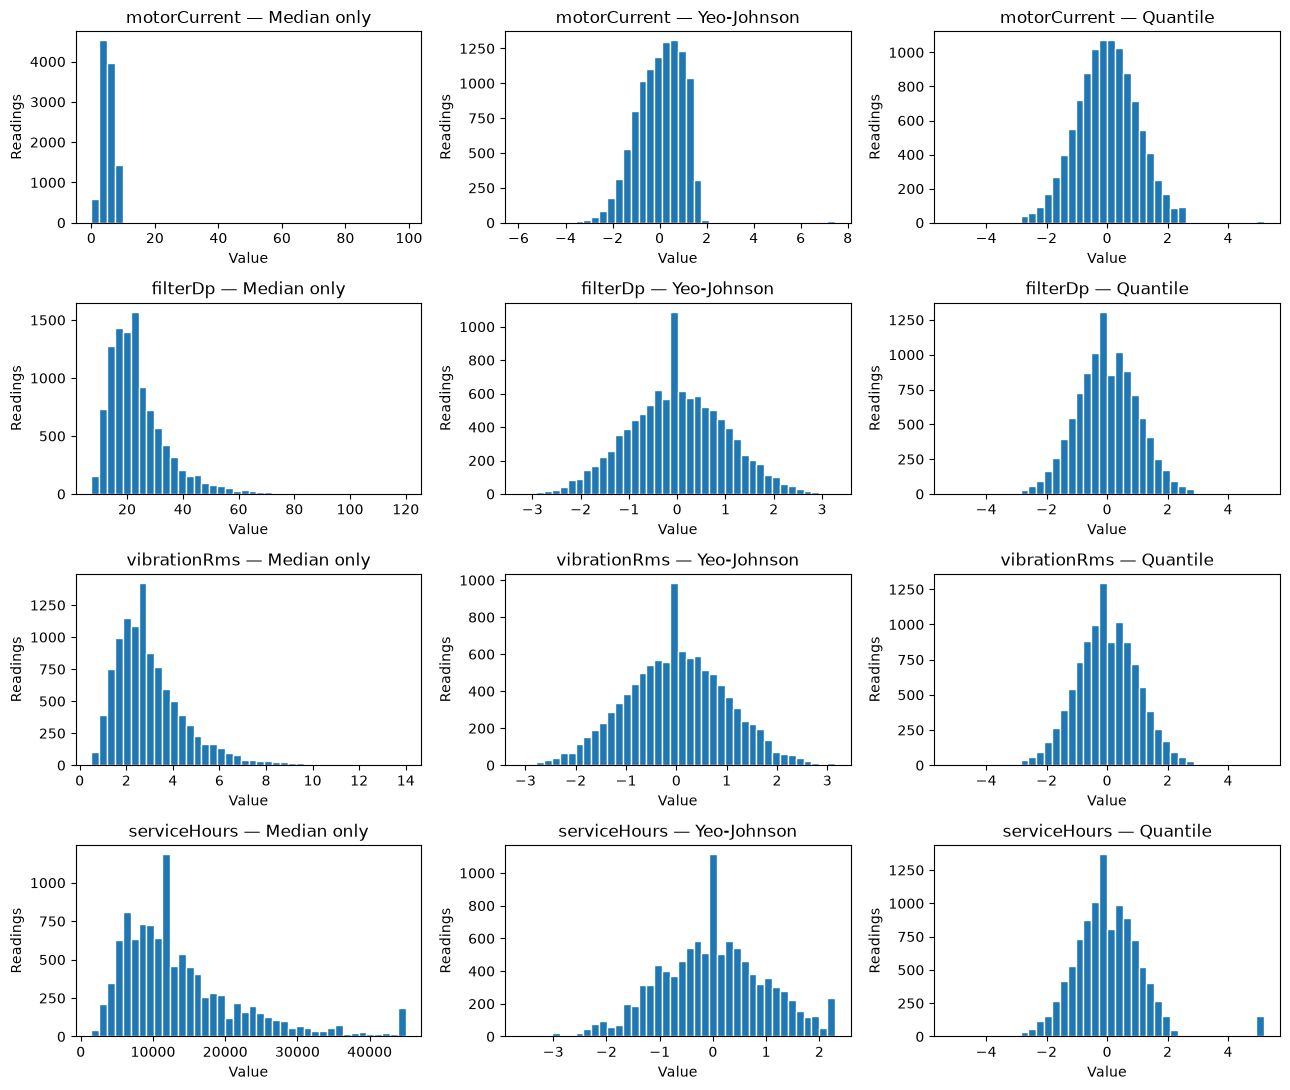

In [17]:
methods = ["Median only", "Yeo-Johnson", "Quantile"]

fig, axes = plt.subplots(4, 3, figsize=(13, 11))

for row, feature in enumerate(plot_features):
    for col, method in enumerate(methods):
        ax = axes[row, col]
        ax.hist(processed_train[method][feature], bins=40, edgecolor="white")
        ax.set_title(f"{feature} — {method}")
        ax.set_xlabel("Value")
        ax.set_ylabel("Readings")

fig.tight_layout()
plt.show()

In [18]:
skewness = pd.DataFrame({
    method: processed_train[method][plot_features].skew()
    for method in methods
})

display(skewness.round(3))

,Median only,Yeo-Johnson,Quantile
motorCurrent,19.210,-0.043,0.108
filterDp,1.915,0.007,-0.010
vibrationRms,1.719,0.005,0.027
serviceHours,1.554,0.000,1.096


Yeo-Johnson reduced skewness close to zero for all four attributes. QuantileTransformer reduced it for three, but serviceHours remained right-skewed (1.096). More symmetric distributions do not guarantee better prediction.


### 2.1(D) - Preprocessing decisions

We chose StandardScaler as the provisional baseline for comparable numeric scales. The other methods remain candidates for predictive comparisons. Feature selection uses this training matrix directly, without reloading an intermediate CSV.


In [19]:
SELECTED_VARIANT = "Standard"
X_train_standard = processed_train[SELECTED_VARIANT].copy()
assert X_train_standard.index.equals(y_train.index)
assert X_train_standard.shape == (10512, 256)
print("Use the in-memory Standard training matrix for Section 2.2.")


Use the in-memory Standard training matrix for Section 2.2.


## 2.2 - Feature Selection

We compared Mutual Information, Logistic Regression RFE and Random Forest using the Standard training matrix and seed 42. We preserved row order and aligned device groups, with the target separate. These are exploratory rankings; test data does not guide selection.


In [20]:
training = X_train_standard.assign(Failure=y_train)
assert training.shape == (10512, 257), "Review the Phase 2.1 export if its schema changed."
assert training.columns.is_unique
X = training.drop(columns="Failure").copy()
y = training["Failure"].copy()
assert X.index.equals(y.index) and X.index.equals(groups_train.index)
assert y.isin([0, 1]).all() and set(y) == {0, 1}
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes)
assert np.isfinite(X.to_numpy()).all()
assert not {"Failure", "unitId", "unit_key", "serialNumber", "ts_cycle"} & set(X.columns)
display(y.value_counts().sort_index().rename("rows").to_frame()
        .assign(percent=lambda d: 100*d["rows"]/len(y)).round(2))
print("Predictors:", X.shape[1], "Rows:", len(X))
print("Repeated complete exported rows:", training.duplicated().sum(), "(retained)")
print("Constant columns:", X.columns[X.nunique(dropna=False).le(1)].to_list())
assert not any(np.array_equal(X[c].to_numpy(), y.to_numpy()) or
               np.array_equal(X[c].to_numpy(), 1-y.to_numpy()) for c in X), "Review a perfect target proxy."


,rows,percent
Failure,,
0,9234,87.84
1,1278,12.16


Predictors: 256 Rows: 10512
Repeated complete exported rows: 0 (retained)
Constant columns: []


### Constant and duplicate columns

For ranking, we kept one copy of identical columns: `unit_metadata_missing` replaced repeated category-missing dummies; `temperatureOil_missing` replaced its identical invalid flag. We recorded aliases without changing the input matrix.

These equalities may not hold in future data. We kept merely correlated features, including filterDp and vibrationRms missingness, separate.


In [21]:
constant_features = X.columns[X.nunique(dropna=False).le(1)].to_list()
priority = ["unit_metadata_missing", "temperatureOil_missing"]
scan_order = [c for c in priority if c in X and c not in constant_features]
scan_order += [c for c in X if c not in scan_order and c not in constant_features]
canonical = []
aliases = {}
for column in scan_order:
    duplicate = None
    for kept in canonical:
        if X[column].equals(X[kept]):
            duplicate = kept
            break
    if duplicate is None:
        canonical.append(column)
    else:
        aliases[column] = duplicate
candidate_names = [c for c in X if c in canonical]
X_candidates = X[candidate_names].copy()
assert not X_candidates.T.duplicated().any()
print("Selection view:", X_candidates.shape)
display(pd.DataFrame([{"duplicate_column": a, "canonical_column": b} for a,b in aliases.items()]))

Selection view: (10512, 250)


,duplicate_column,canonical_column
0,codeLine_missing,unit_metadata_missing
1,class_duty_missing,unit_metadata_missing
2,id_depot_missing,unit_metadata_missing
3,owner_operator_missing,unit_metadata_missing
4,installRegion_missing,unit_metadata_missing
5,temperatureOil_invalid,temperatureOil_missing


In [22]:
numeric_attributes = numeric_features
category_attributes = categorical_features

def original_group(column):
    if column == "unit_metadata_missing":
        return "metadata_availability"
    if column in numeric_attributes:
        return column
    if column.endswith("_missing") and column[:-8] in numeric_attributes:
        return column[:-8]
    if column == "temperatureOil_invalid":
        return "temperatureOil"
    for attribute in category_attributes:
        if column.startswith(attribute + "_"):
            return attribute
    raise ValueError(f"Unrecognised predictor group: {column}")

feature_groups = pd.Series({c: original_group(c) for c in X_candidates}, name="original_group")
display(feature_groups.value_counts().rename("candidate_columns").to_frame())
flag_names = [c for c in X_candidates if c.endswith("_missing")]
flag_rates = X_candidates[flag_names].groupby(y).mean().T.mul(100)
flag_rates.columns = [f"Failure_{label}_percent" for label in flag_rates.columns]
print("Training flag prevalence by Failure (association, not evidence of timing):")
display(flag_rates.round(2))

# Inspect strong correlations among numeric attributes and flags, not all dummy pairs
audit_names = list(dict.fromkeys([c for c in numeric_attributes if c in X_candidates] + flag_names))
corr = X_candidates[audit_names].corr(method="spearman").abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("Strongest absolute Spearman correlations among numbers and flags:")
display(upper.sort_values(ascending=False).head(8).rename("abs_spearman").to_frame().round(3))

,candidate_columns
original_group,
id_depot,120
installRegion,59
owner_operator,40
class_duty,10
codeLine,6
filterDp,2
temperatureOil,2
vibrationRms,2
serviceHours,2


Training flag prevalence by Failure (association, not evidence of timing):


,Failure_0_percent,Failure_1_percent
filterDp_missing,2.11,18.86
vibrationRms_missing,1.91,19.09
temperatureOil_missing,0.26,0.55
serviceHours_missing,5.64,6.18
unit_metadata_missing,0.97,0.86


Strongest absolute Spearman correlations among numbers and flags:


,,abs_spearman
commission_year,serviceHours,0.963
serviceHours_missing,unit_metadata_missing,0.400
filterDp_missing,vibrationRms_missing,0.084
commission_year,vibrationRms_missing,0.051
serviceHours,vibrationRms_missing,0.048
tempBearing,filterDp_missing,0.037
pressure_reservoir,vibrationRms_missing,0.034
commission_year,filterDp_missing,0.029


### 2.2(A1) - Mutual Information

MI measures each feature's association with `Failure`, without giving a direction or testing causality. We treated binary/one-hot columns and commission_year as discrete, using three neighbours and seed 42 for continuous features.

All 250 scores are positive, but small values may reflect noise or repeated readings. MI can miss interactions; a positive score is not a significance test.


In [23]:
binary_mask = pd.Series({c: X_candidates[c].isin([0, 1]).all() for c in X_candidates})
discrete_mask = binary_mask.copy()
discrete_mask.loc["commission_year"] = True
X_mi = X_candidates.copy()
X_mi["commission_year"] = pd.factorize(X_mi["commission_year"], sort=True)[0]
mi_scores = mutual_info_classif(X_mi, y, discrete_features=discrete_mask.to_numpy(),
                              n_neighbors=3, random_state=SEED)
mi_table = pd.DataFrame({"feature": X_candidates.columns, "MI_nats": mi_scores})
mi_table["MI_rank"] = mi_table["MI_nats"].rank(ascending=False, method="average")
mi_table = mi_table.sort_values(["MI_nats", "feature"], ascending=[False, True]).reset_index(drop=True)
assert np.isfinite(mi_scores).all() and (mi_scores >= 0).all()
print("Discrete predictors:", discrete_mask.sum(), "; continuous:", (~discrete_mask).sum())
display(mi_table.head(TOP_K))
display(Markdown("**MI result:** highest scores: " + ", ".join(
    f"{r.feature} ({r.MI_nats:.4f})" for r in mi_table.head(5).itertuples()) +
    f". {int((mi_table.MI_nats > 0).sum())} candidates have positive estimates. "
    "The complete ranking is retained for the combined CSV; these scores are not validated performance."))


Discrete predictors: 241 ; continuous: 9


,feature,MI_nats,MI_rank
0,vibrationRms,0.032167,1.0
1,filterDp,0.032091,2.0
2,vibrationRms_missing,0.025638,3.0
3,filterDp_missing,0.023834,4.0
4,serviceHours,0.010941,5.0
5,commission_year,0.010278,6.0
6,motorCurrent,0.007919,7.0
7,pressure_reservoir,0.007704,8.0
8,tempBearing,0.007448,9.0
9,discharge_dewpoint,0.005238,10.0


**MI result:** highest scores: vibrationRms (0.0322), filterDp (0.0321), vibrationRms_missing (0.0256), filterDp_missing (0.0238), serviceHours (0.0109). 250 candidates have positive estimates. The complete ranking is retained for the combined CSV; these scores are not validated performance.

### 2.2(A2) - Recursive Feature Elimination (RFE)

RFE removes features with small Logistic Regression coefficients. We used L2 regularization, balanced class weights and training-only standardization for comparable coefficients.

We selected 20 exploratory features, removing 10% per step to limit runtime. Selected features share rank 1; we displayed them by coefficient magnitude. Correlation and dummy coding can affect which features remain.


In [24]:
rfe_scaler = StandardScaler()
X_rfe = rfe_scaler.fit_transform(X_candidates)
rfe = RFE(
    estimator=LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000,
                                 class_weight="balanced", random_state=SEED),
    n_features_to_select=TOP_K, step=0.10,
)
with warnings.catch_warnings(record=True) as rfe_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    rfe.fit(X_rfe, y)
assert not any(issubclass(w.category, ConvergenceWarning) for w in rfe_warnings), "Check Logistic Regression convergence."
assert rfe.support_.sum() == TOP_K
rfe_table = pd.DataFrame({"feature": X_candidates.columns,
    "RFE_rank": rfe.ranking_, "RFE_selected": rfe.support_})
rfe_table = rfe_table.sort_values(["RFE_rank", "feature"]).reset_index(drop=True)
selected_rfe = X_candidates.columns[rfe.support_].to_list()
rfe_selected_table = pd.DataFrame({"feature": selected_rfe,
    "coefficient": rfe.estimator_.coef_[0]})
rfe_selected_table["abs_coefficient"] = rfe_selected_table.coefficient.abs()
rfe_selected_table = rfe_selected_table.sort_values(["abs_coefficient", "feature"], ascending=[False, True])
print("RFE ranking (all selected columns have rank 1):")
display(rfe_table.head(TOP_K))
print("Selected columns ordered by final standardized coefficient magnitude:")
display(rfe_selected_table)
display(Markdown(f"**RFE result:** selected {len(selected_rfe)} of {X_candidates.shape[1]} candidates. "
    f"The final fit converged in {int(rfe.estimator_.n_iter_.max())} iterations. "
    "Its largest selected coefficient magnitudes belong to " +
    ", ".join(rfe_selected_table.head(5).feature) +
    ". Signs describe this fitted linear model, not causality or independent significance."))


RFE ranking (all selected columns have rank 1):


,feature,RFE_rank,RFE_selected
0,class_duty_1,1,True
1,class_duty_3,1,True
2,class_duty_H,1,True
3,class_duty_L,1,True
4,class_duty_heavy,1,True
5,class_duty_light,1,True
6,commission_year,1,True
7,discharge_dewpoint,1,True
8,filterDp,1,True
9,filterDp_missing,1,True


Selected columns ordered by final standardized coefficient magnitude:


,feature,coefficient,abs_coefficient
16,id_depot_98.0,-0.545015,0.545015
19,vibrationRms_missing,0.499986,0.499986
18,filterDp_missing,0.498586,0.498586
0,motorCurrent,0.402123,0.402123
15,id_depot_81.0,-0.392711,0.392711
6,commission_year,-0.346462,0.346462
1,filterDp,0.303843,0.303843
4,tempBearing,0.296665,0.296665
12,class_duty_light,0.259702,0.259702
7,class_duty_1,0.248556,0.248556


**RFE result:** selected 20 of 250 candidates. The final fit converged in 17 iterations. Its largest selected coefficient magnitudes belong to id_depot_98.0, vibrationRms_missing, filterDp_missing, motorCurrent, id_depot_81.0. Signs describe this fitted linear model, not causality or independent significance.

### 2.2(A3) - Random Forest Feature Importance

We used 300 trees, minimum leaf size 5, balanced class weights and seed 42. Split-based importance captures nonlinear relationships and interactions; scores sum to 1.

Features with more split points or dummy columns have more chances to contribute. Correlated features may share importance, and training importance does not measure held-out performance.


In [25]:
forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
    class_weight="balanced_subsample", max_features="sqrt", random_state=SEED, n_jobs=2)
forest.fit(X_candidates, y)
rf_table = pd.DataFrame({"feature": X_candidates.columns, "RF_importance": forest.feature_importances_})
rf_table["RF_rank"] = rf_table.RF_importance.rank(ascending=False, method="average")
rf_table = rf_table.sort_values(["RF_importance", "feature"], ascending=[False, True]).reset_index(drop=True)
assert np.isfinite(forest.feature_importances_).all()
assert np.isclose(rf_table.RF_importance.sum(), 1)
display(rf_table.head(TOP_K))
display(Markdown("**Random Forest result:** the leading split-importance features are " +
    ", ".join(f"{r.feature} ({r.RF_importance:.4f})" for r in rf_table.head(5).itertuples()) +
    ". These are fitted training importances, not estimates of generalisation accuracy."))

,feature,RF_importance,RF_rank
0,filterDp,0.091888,1.0
1,filterDp_missing,0.071841,2.0
2,vibrationRms_missing,0.071711,3.0
3,tempBearing,0.070149,4.0
4,serviceHours,0.068918,5.0
5,vibrationRms,0.065555,6.0
6,motorCurrent,0.062007,7.0
7,discharge_dewpoint,0.053316,8.0
8,pressure_reservoir,0.052913,9.0
9,temperatureOil,0.047825,10.0


**Random Forest result:** the leading split-importance features are filterDp (0.0919), filterDp_missing (0.0718), vibrationRms_missing (0.0717), tempBearing (0.0701), serviceHours (0.0689). These are fitted training importances, not estimates of generalisation accuracy.

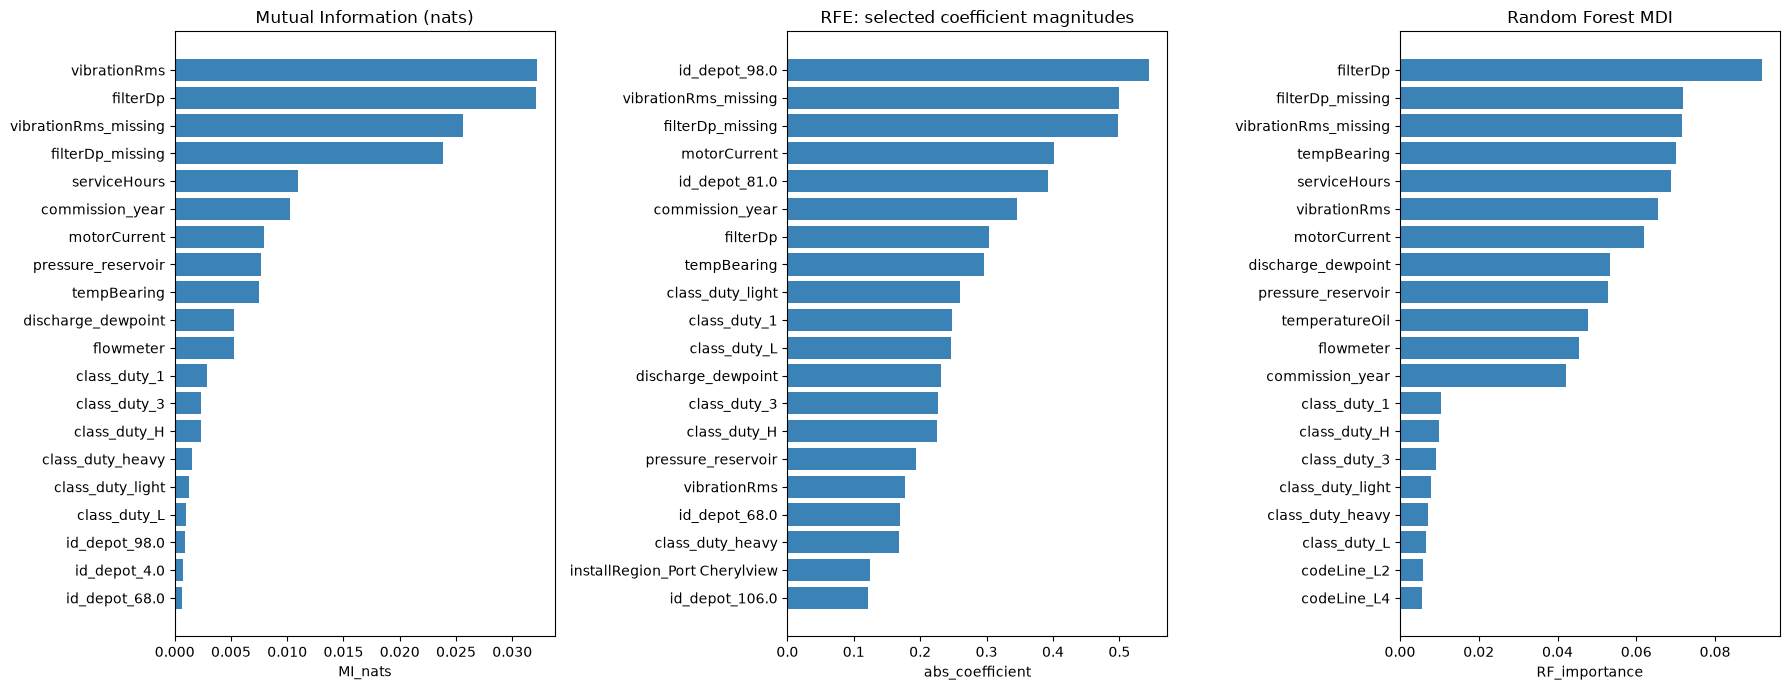

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, table, score, title in [
    (axes[0], mi_table.head(TOP_K), "MI_nats", "Mutual Information (nats)"),
    (axes[1], rfe_selected_table.head(TOP_K), "abs_coefficient", "RFE: selected coefficient magnitudes"),
    (axes[2], rf_table.head(TOP_K), "RF_importance", "Random Forest MDI"),
]:
    view = table.iloc[::-1]
    ax.barh(view.feature, view[score], color="#3B82B6")
    ax.set_title(title)
    ax.set_xlabel(score)
fig.tight_layout()
plt.show()

### 2.2(B) - Rankings and method comparison

We compared the MI and forest top 20 with RFE's 20 selections. We counted appearances and averaged ranks, weighting methods equally and averaging ties. Lower consensus ranks are better; raw scores are not directly comparable.


In [27]:
top_mi = mi_table.loc[mi_table.MI_nats > 0].head(TOP_K).feature.to_list()
top_rfe = rfe_selected_table.feature.to_list()
top_rf = rf_table.loc[rf_table.RF_importance > 0].head(TOP_K).feature.to_list()
display(pd.DataFrame({"MI_top20": pd.Series(top_mi), "RFE_selected20": pd.Series(top_rfe),
                      "RF_top20": pd.Series(top_rf)}).rename_axis("display_position").rename(index=lambda i: i+1))

,MI_top20,RFE_selected20,RF_top20
display_position,,,
1,vibrationRms,id_depot_98.0,filterDp
2,filterDp,vibrationRms_missing,filterDp_missing
3,vibrationRms_missing,filterDp_missing,vibrationRms_missing
4,filterDp_missing,motorCurrent,tempBearing
5,serviceHours,id_depot_81.0,serviceHours
6,commission_year,commission_year,vibrationRms
7,motorCurrent,filterDp,motorCurrent
8,pressure_reservoir,tempBearing,discharge_dewpoint
9,tempBearing,class_duty_light,pressure_reservoir


In [28]:
ranking = (mi_table.set_index("feature").join(rfe_table.set_index("feature"))
           .join(rf_table.set_index("feature")))
ranking["RFE_comparison_rank"] = ranking.RFE_rank.rank(ascending=True, method="average")
ranking["mean_rank"] = ranking[["MI_rank", "RFE_comparison_rank", "RF_rank"]].mean(axis=1)
ranking["consensus_rank"] = ranking.mean_rank.rank(method="min")
ranking["MI_top20"] = ranking.index.isin(top_mi)
ranking["RFE_top20"] = ranking.index.isin(top_rfe)
ranking["RF_top20"] = ranking.index.isin(top_rf)
ranking["top20_votes"] = ranking[["MI_top20", "RFE_top20", "RF_top20"]].sum(axis=1)
ranking["original_group"] = feature_groups
ranking = ranking.sort_values(["mean_rank", "feature"])
assert not ranking.isna().any().any()
assert set(ranking.index) == set(X_candidates.columns)
print("Consensus ranking (full ranking is saved in Section 7):")
display(ranking.head(TOP_K).round(4))
print("Features receiving at least two top-20 votes:")
display(ranking.loc[ranking.top20_votes.ge(2),
    ["original_group", "MI_rank", "RFE_rank", "RF_rank", "top20_votes", "mean_rank"]].round(2))

sets = {"MI": set(top_mi), "RFE": set(top_rfe), "RF": set(top_rf)}
agreement = pd.DataFrame([[len(a & b) for b in sets.values()] for a in sets.values()],
    index=sets.keys(), columns=sets.keys())
print("Pairwise top-list overlap (counts):")
display(agreement)
print("In all three lists:", sorted(set.intersection(*sets.values())))

Consensus ranking (full ranking is saved in Section 7):


,MI_nats,MI_rank,RFE_rank,RFE_selected,RF_importance,RF_rank,RFE_comparison_rank,mean_rank,consensus_rank,MI_top20,RFE_top20,RF_top20,top20_votes,original_group
feature,,,,,,,,,,,,,,
filterDp,0.0321,2.0,1,True,0.0919,1.0,10.5,4.5000,1.0,True,True,True,3,filterDp
filterDp_missing,0.0238,4.0,1,True,0.0718,2.0,10.5,5.5000,2.0,True,True,True,3,filterDp
vibrationRms_missing,0.0256,3.0,1,True,0.0717,3.0,10.5,5.5000,2.0,True,True,True,3,vibrationRms
vibrationRms,0.0322,1.0,1,True,0.0656,6.0,10.5,5.8333,4.0,True,True,True,3,vibrationRms
tempBearing,0.0074,9.0,1,True,0.0701,4.0,10.5,7.8333,5.0,True,True,True,3,tempBearing
motorCurrent,0.0079,7.0,1,True,0.0620,7.0,10.5,8.1667,6.0,True,True,True,3,motorCurrent
pressure_reservoir,0.0077,8.0,1,True,0.0529,9.0,10.5,9.1667,7.0,True,True,True,3,pressure_reservoir
commission_year,0.0103,6.0,1,True,0.0421,12.0,10.5,9.5000,8.0,True,True,True,3,commission_year
discharge_dewpoint,0.0052,10.0,1,True,0.0533,8.0,10.5,9.5000,8.0,True,True,True,3,discharge_dewpoint


Features receiving at least two top-20 votes:


,original_group,MI_rank,RFE_rank,RF_rank,top20_votes,mean_rank
feature,,,,,,
filterDp,filterDp,2.0,1,1.0,3,4.50
filterDp_missing,filterDp,4.0,1,2.0,3,5.50
vibrationRms_missing,vibrationRms,3.0,1,3.0,3,5.50
vibrationRms,vibrationRms,1.0,1,6.0,3,5.83
tempBearing,tempBearing,9.0,1,4.0,3,7.83
motorCurrent,motorCurrent,7.0,1,7.0,3,8.17
pressure_reservoir,pressure_reservoir,8.0,1,9.0,3,9.17
commission_year,commission_year,6.0,1,12.0,3,9.50
discharge_dewpoint,discharge_dewpoint,10.0,1,8.0,3,9.50


Pairwise top-list overlap (counts):


,MI,RFE,RF
MI,20,17,17
RFE,17,20,15
RF,17,15,20


In all three lists: ['class_duty_1', 'class_duty_3', 'class_duty_H', 'class_duty_L', 'class_duty_heavy', 'class_duty_light', 'commission_year', 'discharge_dewpoint', 'filterDp', 'filterDp_missing', 'motorCurrent', 'pressure_reservoir', 'tempBearing', 'vibrationRms', 'vibrationRms_missing']


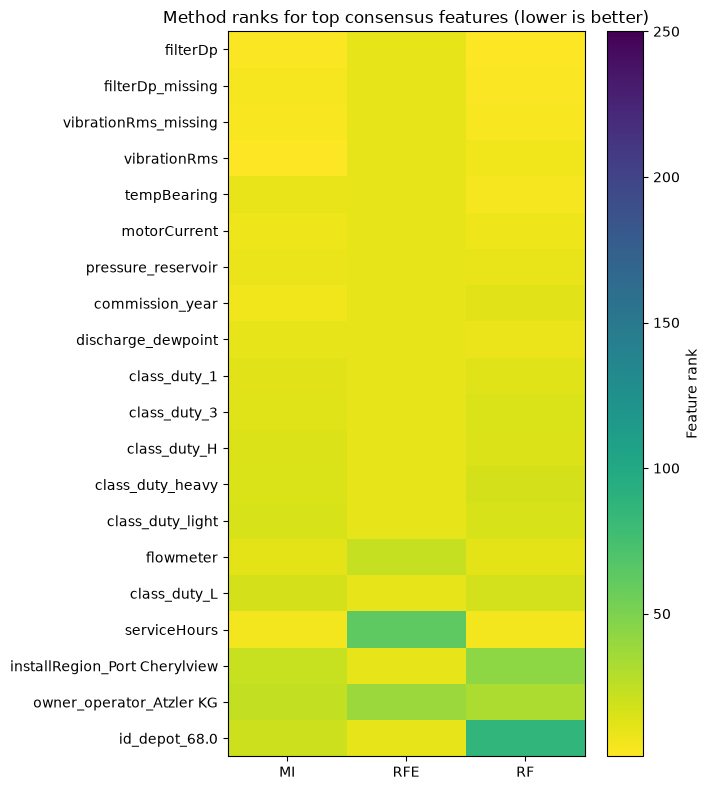

In [29]:
heat = ranking.head(TOP_K)[["MI_rank", "RFE_comparison_rank", "RF_rank"]]
fig, ax = plt.subplots(figsize=(7, 8))
plot = ax.imshow(heat, aspect="auto", vmin=1, vmax=len(ranking), cmap="viridis_r")
ax.set_xticks([0, 1, 2], labels=["MI", "RFE", "RF"])
ax.set_yticks(range(len(heat)), labels=heat.index)
ax.set_title("Method ranks for top consensus features (lower is better)")
fig.colorbar(plot, ax=ax, label="Feature rank")
fig.tight_layout()
plt.show()

#### Original feature groups

We grouped measurements with missingness flags and categories with one-hot columns. A group receives a vote when any column enters a method's top list; group ranks summarize each method's best column. RF group scores sum importances; MI group scores use the maximum, not joint MI.

This voting rule favours high-cardinality attributes: more columns mean more chances to enter the top 20. A few highly ranked depot columns can therefore admit all 120 columns. Metadata-missing aliases are represented by the canonical availability flag.


In [30]:
group_ranking = ranking.groupby("original_group").agg(
    candidate_columns=("mean_rank", "size"), MI_max_nats=("MI_nats", "max"),
    RF_group_MDI=("RF_importance", "sum"), RFE_selected_columns=("RFE_selected", "sum"),
    MI_vote=("MI_top20", "max"), RFE_vote=("RFE_top20", "max"), RF_vote=("RF_top20", "max"),
    best_MI_rank=("MI_rank", "min"), best_RFE_rank=("RFE_comparison_rank", "min"),
    best_RF_rank=("RF_rank", "min"),
)
group_ranking["method_votes"] = group_ranking[["MI_vote", "RFE_vote", "RF_vote"]].sum(axis=1)
group_ranking["mean_best_child_rank"] = group_ranking[["best_MI_rank", "best_RFE_rank", "best_RF_rank"]].mean(axis=1)
group_ranking = group_ranking.sort_values(["method_votes", "mean_best_child_rank"], ascending=[False, True])
display(group_ranking.round(4))
display(Markdown("**Comparison:** MI/RFE overlap = " + str(agreement.loc["MI", "RFE"]) +
    ", MI/RF = " + str(agreement.loc["MI", "RF"]) + ", RFE/RF = " + str(agreement.loc["RFE", "RF"]) +
    ". Groups supported by at least two methods: " +
    ", ".join(group_ranking.index[group_ranking.method_votes.ge(2)]) +
    ". Different ranks are expected: MI is univariate, RFE is linear and conditional, "
    "and forests can use nonlinear splits and interactions. Redundancy can change which representative is favoured."))


,candidate_columns,MI_max_nats,RF_group_MDI,RFE_selected_columns,MI_vote,RFE_vote,RF_vote,best_MI_rank,best_RFE_rank,best_RF_rank,method_votes,mean_best_child_rank
original_group,,,,,,,,,,,,
filterDp,2,0.0321,0.1637,2,True,True,True,2.0,10.5,1.0,3,4.5000
vibrationRms,2,0.0322,0.1373,2,True,True,True,1.0,10.5,3.0,3,4.8333
tempBearing,1,0.0074,0.0701,1,True,True,True,9.0,10.5,4.0,3,7.8333
motorCurrent,1,0.0079,0.0620,1,True,True,True,7.0,10.5,7.0,3,8.1667
pressure_reservoir,1,0.0077,0.0529,1,True,True,True,8.0,10.5,9.0,3,9.1667
commission_year,1,0.0103,0.0421,1,True,True,True,6.0,10.5,12.0,3,9.5000
discharge_dewpoint,1,0.0052,0.0533,1,True,True,True,10.0,10.5,8.0,3,9.5000
class_duty,10,0.0029,0.0677,6,True,True,True,12.0,10.5,13.0,3,11.8333
flowmeter,1,0.0052,0.0455,0,True,False,True,11.0,23.0,11.0,2,15.0000


**Comparison:** MI/RFE overlap = 17, MI/RF = 17, RFE/RF = 15. Groups supported by at least two methods: filterDp, vibrationRms, tempBearing, motorCurrent, pressure_reservoir, commission_year, discharge_dewpoint, class_duty, flowmeter, id_depot, serviceHours. Different ranks are expected: MI is univariate, RFE is linear and conditional, and forests can use nonlinear splits and interactions. Redundancy can change which representative is favoured.

### 2.2(C) - Candidate feature subsets

We retained two candidates from the same rankings:

- **with_depot:** 142 columns from 11 groups, including all 120 depot columns.
- **without_depot:** 22 columns from the other 10 groups; only id_depot was removed.

Depot may capture useful operating conditions, but its many columns add complexity and may fit location-specific patterns that do not transfer. Removing it reduces direct location dependence, not all device/location proxies.

Section 2.3 uses these computed lists. Neither subset is proven better; Phase 3 requires proper validation.


In [31]:
selected_groups = group_ranking.index[group_ranking.method_votes.ge(2)].to_list()
selected_features = [c for c in X_candidates if feature_groups[c] in selected_groups]
X_selected = X[selected_features].copy()
assert X_selected.index.equals(y.index) and len(X_selected) == 10512
assert np.isfinite(X_selected.to_numpy()).all()
ranking["proposed_selected"] = ranking.index.isin(selected_features)
print(f"Proposed subset: {len(selected_features)} encoded features from {len(selected_groups)} groups.")
display(group_ranking.loc[selected_groups, ["candidate_columns", "method_votes", "mean_best_child_rank"]].round(2))
display(pd.Series(selected_features, name="selected_feature").to_frame())

# Keep the original candidate and remove only depot from the second candidate
depot_features = [c for c in selected_features if feature_groups[c] == "id_depot"]
compact_groups = [g for g in selected_groups if g != "id_depot"]
compact_features = [c for c in selected_features if feature_groups[c] != "id_depot"]
assert depot_features and compact_features
assert set(selected_features) - set(compact_features) == set(depot_features)
X_compact = X[compact_features].copy()
assert X_compact.index.equals(y.index) and len(X_compact) == len(X_selected)
assert np.isfinite(X_compact.to_numpy()).all()

Proposed subset: 142 encoded features from 11 groups.


,candidate_columns,method_votes,mean_best_child_rank
original_group,,,
filterDp,2,3,4.50
vibrationRms,2,3,4.83
tempBearing,1,3,7.83
motorCurrent,1,3,8.17
pressure_reservoir,1,3,9.17
commission_year,1,3,9.50
discharge_dewpoint,1,3,9.50
class_duty,10,3,11.83
flowmeter,1,2,15.00


,selected_feature
0,motorCurrent
1,filterDp
2,pressure_reservoir
3,vibrationRms
4,flowmeter
...,...
137,id_depot_98.0
138,id_depot_99.0
139,filterDp_missing
140,vibrationRms_missing


In [32]:
subset_comparison = pd.DataFrame([
    {"candidate": "with_depot", "columns": len(selected_features),
     "group_count": len(selected_groups), "original_groups": ", ".join(selected_groups),
     "advantages": "Preserves all groups supported by voting, including possible depot information.",
     "limitations": "120 depot dummies add complexity and risk fitting location-specific patterns."},
    {"candidate": "without_depot", "columns": len(compact_features),
     "group_count": len(compact_groups), "original_groups": ", ".join(compact_groups),
     "advantages": "Simpler; no direct depot encoding; all other selected groups preserved.",
     "limitations": "May lose useful depot information; other location proxies and timing risks remain."},
]).set_index("candidate")
print("Two exploratory candidates; rankings are unchanged:")
with pd.option_context("display.max_colwidth", None):
    display(subset_comparison)

Two exploratory candidates; rankings are unchanged:


,columns,group_count,original_groups,advantages,limitations
candidate,,,,,
with_depot,142,11,"filterDp, vibrationRms, tempBearing, motorCurrent, pressure_reservoir, commission_year, discharge_dewpoint, class_duty, flowmeter, id_depot, serviceHours","Preserves all groups supported by voting, including possible depot information.",120 depot dummies add complexity and risk fitting location-specific patterns.
without_depot,22,10,"filterDp, vibrationRms, tempBearing, motorCurrent, pressure_reservoir, commission_year, discharge_dewpoint, class_duty, flowmeter, serviceHours",Simpler; no direct depot encoding; all other selected groups preserved.,May lose useful depot information; other location proxies and timing risks remain.


In [33]:
# Keep the old top-level list for compatibility; both named candidates are explicit
feature_subsets = {
    "with_depot": {"selected_features": selected_features,
                   "selected_original_groups": selected_groups},
    "without_depot": {"selected_features": compact_features,
                      "selected_original_groups": compact_groups},
}
for subset in feature_subsets.values():
    names = subset["selected_features"]
    assert len(names) == len(set(names)) and set(names) <= set(X.columns)
    assert "Failure" not in names
    subset["column_count"] = len(names)
    subset["group_count"] = len(subset["selected_original_groups"])

specification = {
    "source": "In-memory Standard training matrix from Section 2.1", "preprocessing_variant": "Standard",
    "training_rows": len(X), "input_predictors": X.shape[1],
    "candidate_predictors": X_candidates.shape[1], "seed": SEED,
    "top_k_per_method": TOP_K, "legacy_subset_name": "with_depot",
    "selected_features": selected_features, "selected_original_groups": selected_groups,
    "duplicate_aliases": aliases, "constant_columns": constant_features,
    "feature_subsets": feature_subsets,
}


### Feature-selection findings

All methods share 15 top-list features, including filterDp, vibrationRms, their missingness flags, tempBearing and motorCurrent. MI/RFE and MI/forest each overlap on 17 features; RFE/forest overlap on 15. ServiceHours ranks highly for MI and the forest but is not among RFE's 20 selections.

The compact subset retains nine numeric attribute groups and class_duty. Owner/operator and installation region did not meet the group-voting threshold; this does not prove they are irrelevant.

Missingness may reflect reporting or failure-recording procedures. Its availability before prediction, and metadata timing including serviceHours, remain unverified; a perfect-proxy check cannot rule out leakage. Balanced class weights address imbalance, but frequently measured devices still have more influence.


## 2.3 - Reproducible Preprocessing Pipeline

### 2.3(A-B) - Reuse of the fitted Standard Pipeline

We reused the Standard Pipeline fitted in Section 2.1. Its ColumnTransformer applies training-median imputation and StandardScaler to numbers, OneHotEncoder to categories, and passes flags through. Unknown categories do not create new columns.


In [34]:
preprocessor = fitted_preprocessors[SELECTED_VARIANT]
display(preprocessor)
X_train_processed = preprocessor.transform(X_train_prepared)
pd.testing.assert_frame_equal(X_train_processed, X_train_standard, check_dtype=False)
assert X_train_processed.shape == (10512, 256)
numeric_fitted = preprocessor.named_steps["columns"].named_transformers_["numeric"]
imputer = numeric_fitted.named_steps["imputer"]
scaler = numeric_fitted.named_steps["transformer"]
np.testing.assert_allclose(imputer.statistics_, X_train_prepared[numeric_features].median().fillna(0).to_numpy())
assert int(scaler.n_samples_seen_) == len(train)
print("The fitted Standard pipeline reproduces the training matrix used for selection.")


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](31,)","['unitId','ts_cycle','motorCurrent',...,'vibrationRms_missing', 'temperatureOil_missing','serviceHours_missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,31
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_ou

The fitted Standard pipeline reproduces the training matrix used for selection.


In [35]:
display(pd.DataFrame({"training_missing": X_train_prepared[numeric_features].isna().sum(),
    "fitted_median": imputer.statistics_, "fitted_mean": scaler.mean_,
    "fitted_scale": scaler.scale_}).round(4))


,training_missing,fitted_median,fitted_mean,fitted_scale
motorCurrent,0,5.0351,5.2562,3.6585
filterDp,436,21.3841,24.0145,11.1128
temperatureOil,31,54.8080,54.8488,12.0201
pressure_reservoir,0,8.7148,8.7116,0.6012
vibrationRms,420,2.7188,3.0472,1.5925
flowmeter,0,28.0728,28.0116,4.0122
tempBearing,0,65.0403,65.0165,8.0435
discharge_dewpoint,0,7.9881,7.9944,3.5041
commission_year,101,2021.0000,2020.5212,2.5181
serviceHours,600,11563.4000,13857.0388,8615.5744


### Test-data transformation

We applied the same fixed preparation, then called `transform` only. We verified matching columns and unchanged training medians and means. Test labels remained separate until export.


In [36]:
X_test_raw = test.drop(columns="Failure")
y_test = test["Failure"].copy()
groups_test = test["unit_key"].copy()
X_test_prepared = prepare_inputs(X_test_raw)
training_medians = imputer.statistics_.copy()
training_means = scaler.mean_.copy()
X_test_processed = preprocessor.transform(X_test_prepared)
np.testing.assert_array_equal(imputer.statistics_, training_medians)
np.testing.assert_array_equal(scaler.mean_, training_means)
assert int(scaler.n_samples_seen_) == len(train)
assert X_test_processed.shape == (2580, 256)
assert X_test_processed.columns.equals(X_train_processed.columns)
assert X_test_processed.index.equals(y_test.index)
print("Test transformed without refitting; all 256 names and their order match train.")


Test transformed without refitting; all 256 names and their order match train.


### Both computed subsets

We selected computed names with `.loc` in matching train/test order. Missing columns stop execution. Integer flags and their float equivalents have the same values.


In [37]:
train_subsets = {}
test_subsets = {}
for name, definition in feature_subsets.items():
    names = definition["selected_features"]
    assert len(names) == len(set(names)) == definition["column_count"]
    assert set(names) <= set(X_train_processed.columns) and "Failure" not in names
    train_subsets[name] = X_train_processed.loc[:, names].copy()
    test_subsets[name] = X_test_processed.loc[:, names].copy()
    assert train_subsets[name].columns.equals(test_subsets[name].columns)
assert train_subsets["with_depot"].shape[1] == 142
assert train_subsets["without_depot"].shape[1] == 22
assert not any(c.startswith("id_depot_") for c in train_subsets["without_depot"])

schema_summary = pd.DataFrame([
    {"variant": name, "train_rows": len(a), "test_rows": len(b),
     "train_features": a.shape[1], "test_features": b.shape[1],
     "same_column_order": a.columns.equals(b.columns)}
    for name, a, b in [("Standard full", X_train_processed, X_test_processed)] +
        [(name, train_subsets[name], test_subsets[name]) for name in train_subsets]
]).set_index("variant")
display(schema_summary)


,train_rows,test_rows,train_features,test_features,same_column_order
variant,,,,,
Standard full,10512,2580,256,256,True
with_depot,10512,2580,142,142,True
without_depot,10512,2580,22,22,True


### Validation checks

We verified finite numeric outputs, target alignment, disjoint devices and agreement with the earlier Standard matrix. A two-row probe checks missing/unseen categories and invalid versus originally missing oil, without changing the fitted vocabulary or columns.


In [38]:
frames = {"train_full": X_train_processed, "test_full": X_test_processed}
frames.update({f"train_{k}": v for k,v in train_subsets.items()})
frames.update({f"test_{k}": v for k,v in test_subsets.items()})
for name, frame in frames.items():
    assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in frame.dtypes)
    assert np.isfinite(frame.to_numpy(dtype=float)).all(), name
    expected_index = y_train.index if name.startswith("train_") else y_test.index
    assert frame.index.equals(expected_index), name
assert set(groups_train).isdisjoint(groups_test)

probe_raw = X_train_raw.iloc[:2].copy()
for column in categorical_features:
    probe_raw[column] = [f"__unseen_{column}__", None]
probe_raw["temperatureOil"] = [-999, np.nan]
probe = prepare_inputs(probe_raw)
assert probe.temperatureOil_invalid.to_list() == [1, 0]
assert probe.temperatureOil_missing.to_list() == [1, 1]
probe_processed = preprocessor.transform(probe)
assert probe_processed.columns.equals(X_train_processed.columns)
assert np.isfinite(probe_processed.to_numpy(dtype=float)).all()
for column in categorical_features:
    dummy_columns = [c for c in probe_processed if c.startswith(column + "_")]
    assert probe_processed.loc[probe_processed.index[0], dummy_columns].eq(0).all()
print("PASS: numeric/finite outputs, group separation, target alignment, reproduced split and preprocessing.")
print("PASS: unseen/missing categories, distinct invalid/missing oil flags and unchanged fitted state.")


PASS: numeric/finite outputs, group separation, target alignment, reproduced split and preprocessing.
PASS: unseen/missing categories, distinct invalid/missing oil flags and unchanged fitted state.


### Final exports and local reuse

We saved rankings, feature lists, four labelled datasets and row/device mappings under `data/processed/phase2_final/`. We reloaded CSVs and verified values, column order and labels.

The joblib bundle stores the fitted pipeline and feature lists. New joined inputs require one `prepare_inputs` call, transformation and selection by saved names. Integration and preparation remain outside the artifact; reuse requires consistent category formats and library versions. Joblib files must come from trusted sources.


In [39]:
FINAL_DIR.mkdir(parents=True, exist_ok=True)
ranking.to_csv(FINAL_DIR / "feature_ranking.csv", index_label="feature")
group_ranking.to_csv(FINAL_DIR / "group_ranking.csv", index_label="original_group")
SELECTION_JSON = FINAL_DIR / "selected_features.json"
SELECTION_JSON.write_text(json.dumps(specification, indent=2) + "\n", encoding="utf-8")
assert json.loads(SELECTION_JSON.read_text())["feature_subsets"] == feature_subsets


In [40]:
FINAL_DIR.mkdir(parents=True, exist_ok=True)
export_rows = []
for name in train_subsets:
    for partition, features, target in [
        ("train", train_subsets[name], y_train), ("test", test_subsets[name], y_test)]:
        assert features.index.equals(target.index)
        exported = features.assign(Failure=target)
        output = FINAL_DIR / f"{partition}_{name}.csv"
        exported.to_csv(output, index=False)
        loaded = pd.read_csv(output)
        assert loaded.columns.to_list() == list(features.columns) + ["Failure"]
        assert loaded.shape == exported.shape
        np.testing.assert_allclose(loaded.to_numpy(dtype=float), exported.to_numpy(dtype=float), rtol=1e-10, atol=1e-10)
        np.testing.assert_array_equal(loaded.Failure, target.to_numpy())
        export_rows.append({"file": output.name, "rows": len(loaded),
                            "features": features.shape[1], "bytes": output.stat().st_size})

In [41]:
row_manifest = pd.concat([
    pd.DataFrame({"partition": name, "export_row": np.arange(len(part)),
        "reading_row_id": part.index.to_numpy(), "unitId": part.unitId.to_numpy(),
        "unit_key": part.unit_key.to_numpy()})
    for name,part in [("train", train), ("test", test)]
], ignore_index=True)
assert row_manifest.reading_row_id.is_unique
ROW_MANIFEST = FINAL_DIR / "split_rows.csv"
row_manifest.to_csv(ROW_MANIFEST, index=False)
pd.testing.assert_frame_equal(pd.read_csv(ROW_MANIFEST), row_manifest, check_dtype=False)

# Learned parameters and saved column lists are enough for prepared inputs

In [42]:
bundle = {
    "preprocessor": preprocessor,
    "feature_subsets": feature_subsets,
    "input_contract": "Call prepare_inputs once on joined non-target data before transform.",
    "sklearn_version": sklearn.__version__,
}
ARTIFACT = FINAL_DIR / "preprocessing.joblib"
joblib.dump(bundle, ARTIFACT)
restored_bundle = joblib.load(ARTIFACT)
restored_test = restored_bundle["preprocessor"].transform(X_test_prepared)
for name, definition in restored_bundle["feature_subsets"].items():
    names = definition["selected_features"]
    pd.testing.assert_frame_equal(restored_test.loc[:, names], test_subsets[name])

manifest = {
    "split_config": SPLIT_CONFIG, "split_rows_file": ROW_MANIFEST.name,
    "training_rows": len(train), "test_rows": len(test), "full_features": X_train_processed.shape[1],
    "versions": {"sklearn": sklearn.__version__, "pandas": pd.__version__,
                 "numpy": np.__version__, "joblib": joblib.__version__},
    "artifact": ARTIFACT.name, "input_contract": bundle["input_contract"],
    "exports": export_rows,
}
MANIFEST = FINAL_DIR / "manifest.json"
MANIFEST.write_text(json.dumps(manifest, indent=2) + "\n", encoding="utf-8")
print("CSV, row/group mapping and artifact reload passed.")
display(pd.DataFrame(export_rows))
print("Additional outputs:", ROW_MANIFEST.name, ARTIFACT.name, MANIFEST.name)

CSV, row/group mapping and artifact reload passed.


,file,rows,features,bytes
0,train_with_depot.csv,10512,142,7426980
1,test_with_depot.csv,2580,142,1824444
2,train_without_depot.csv,10512,22,2379530
3,test_without_depot.csv,2580,22,584354


Additional outputs: split_rows.csv preprocessing.joblib manifest.json


## Conclusions

We compared three scalers and two distribution transformers. StandardScaler remains the baseline; predictive performance has not yet been compared.

MI, RFE and Random Forest share 15 top-list features. We retained both candidates for Phase 3: 142 columns with depot and 22 without it. Neither is proven optimal.

The same training-fitted pipeline transforms test data without refitting. Exported datasets, feature lists, device mappings and the fitted artifact are ready for reuse.

Phase 3 requires fold-fitted preprocessing and feature selection with device-grouped validation. The current selections used all training labels and are not independent of those folds. The test set is reserved for final evaluation; prediction-time availability of missingness and metadata still needs verification.
